# Unlabelled autoencoder on the T = 32 benign + GridSybil windows (all/T32_benign_grid)

The missing cell of the baseline grid: the 1D-conv autoencoder of `task/autoencoder_benign_t32` (14 × 32 in, z = 16,
63,293 parameters, same optimiser / LR schedule / early stopping) trained on **every train window pooled, benign and
GridSybil mixed, with no label read** — the protocol of `task/autoencoder_overlap`, at T = 32 on
`src/data/encoder_input/all/T32_benign_grid/` (benign of all 8 scenario folders + GridSybil; train / val / test =
85 / 7.5 / 7.5 by vehicle key, fixed on disk). Val (mixed, unlabelled) drives early stopping, the LR schedule and the
p95 / p99 alarm thresholds. The test split is scored first; its labels are read afterwards (section 5).

Two label-free scores per window: the reconstruction error (masked MSE over real rows) and the **Mahalanobis
distance** of z to a Gaussian fitted on the train z. Each is also aggregated per **track** (one link): max and mean.

One seed, a side experiment, not a thesis result (RULE 1). This notebook runs from the repo root and reads the run
folder written by `python -m task.autoencoder_t32.train` and `python -m task.autoencoder_t32.evaluate`. Sections:
1 input, 2 model, 3 training record, 4 reconstruction on val, 5 test, 6 context, 7 analysis.

Setup: repo-root check, package imports, the run folder (the newest `runs/*/evaluation.json`).

In [1]:
import json
from pathlib import Path

assert Path("task/autoencoder_t32/config.py").is_file(), "run this notebook from the repo root"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score

from task.autoencoder_benign_t32.model import ConvAutoencoder, count_params
from task.autoencoder_t32.config import TOTAL_PARAMS, AutoencoderT32Config
from task.autoencoder_t32.data import UnlabelledWindows
from task.autoencoder_t32.labels import WindowLabels
from task.autoencoder_t32.scoring import SCORES, Evaluation, Mahalanobis, ScoreFiles, TrackScores, quantile_thresholds
from task.autoencoder_t32.trainer import Trainer

pd.set_option("display.width", 200, "display.max_columns", 30)
RUN = max(Path("task/autoencoder_t32/runs").glob("*/evaluation.json"), key=lambda p: p.stat().st_mtime).parent
settings = AutoencoderT32Config.from_dict(json.loads((RUN / "config.json").read_text()))
summary = json.loads((RUN / "summary.json").read_text())
stored = json.loads((RUN / "evaluation.json").read_text())
env = json.loads((RUN / "env.json").read_text())
META = json.loads((Path(settings.data_dir) / "metadata.json").read_text())
FEATURES = META["features"]
print("run folder:", RUN, "| seed", settings.seed, "| device", env["device"], "| torch", env["torch"])
print("labels read in training:", summary["labels_read"], "| label-file guard:", summary["label_file_guard"])

run folder: task/autoencoder_t32/runs/seed0 | seed 0 | device mps | torch 2.14.1
labels read in training: False | label-file guard: {'process': True, 'workers': True}


## 1. Input

Train and val as the training code sees them: `UnlabelledWindows` reads the feature shards (id, x, mask) only and has
no label or info attribute. The class counts of the splits are shown in section 5, from the info files.

In [2]:
train = UnlabelledWindows.load(settings.data_dir, "train", settings.workers, cache_dir=settings.cache_dir)
val = UnlabelledWindows.load(settings.data_dir, "val", settings.workers, cache_dir=settings.cache_dir)
print("attributes of the training dataset object:", UnlabelledWindows.__slots__)
assert not (train.vehicles() & val.vehicles()), "a sender vehicle is in both train and val"
rows = []
for d in (train, val):
    n = d.n_messages
    rows.append({"split": d.split, "windows": len(d), "tracks": len(set(d.tracks().tolist())), "vehicles": len(d.vehicles()),
                 "median rows": np.median(n), "mean rows": round(n.mean(), 2), "share = 32": round(float((n == 32).mean()), 3),
                 "share 1-3": round(float((n <= 3).mean()), 3), "padding share": round(1 - d.mask.mean(), 3)})
display(pd.DataFrame(rows).set_index("split"))
print("window shape", train.x.shape[1:], "+ mask; model input (channels x time):", (settings.n_features + 1, settings.seq_len))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(train.n_messages, bins=np.arange(1, 34) - 0.5, color="tab:blue")
ax.set_xlabel("real messages per window"); ax.set_ylabel("train windows"); ax.set_yscale("log")
ax.set_title("Train (unlabelled mix): real messages per window")
plt.show()

attributes of the training dataset object: ('split', 'x', 'mask', 'ids', 'n_messages')


,windows,tracks,vehicles,median rows,mean rows,share = 32,share 1-3,padding share
split,,,,,,,,
train,779087,622303,5933,14.0,16.24,0.211,0.152,0.492
val,67582,54404,524,14.0,16.11,0.205,0.158,0.497


window shape (32, 13) + mask; model input (channels x time): (14, 32)


/var/folders/db/lskr0w394ng50mbc22ygfkn00000gn/T/ipykernel_50742/109183548.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Per-feature statistics over the **real** train rows (normalised with the train mean / std, so ≈ 0 / 1).

In [3]:
real = train.x[train.mask]
pd.DataFrame({"mean": real.mean(0), "std": real.std(0), "min": real.min(0), "max": real.max(0)}, index=FEATURES).round(3)

,mean,std,min,max
claimed_pos_x,0.000,0.989,-21.510000,14.705000
claimed_pos_y,-0.000,0.985,-27.315001,23.822001
rx_pos_x,-0.000,0.997,-1.153000,2.360000
rx_pos_y,-0.000,1.002,-2.031000,2.366000
claimed_vel_x,-0.000,0.990,-2.905000,2.918000
claimed_vel_y,-0.000,0.989,-2.658000,2.546000
rx_vel_x,-0.000,0.991,-2.630000,2.573000
rx_vel_y,-0.000,0.991,-2.327000,2.228000
claimed_acl_x,-0.000,0.991,-4.943000,4.944000
claimed_acl_y,0.000,0.989,-3.636000,3.661000


## 2. Model

The `task/autoencoder_benign_t32` ConvAutoencoder, imported unchanged: layers with their output shapes for a batch of
2 windows, and the trainable parameter count (asserted).

In [4]:
model = ConvAutoencoder(settings)
x0, m0 = torch.zeros(2, settings.seq_len, settings.n_features), torch.ones(2, settings.seq_len, dtype=torch.bool)
table, hooks = [], []
layer_types = (torch.nn.Conv1d, torch.nn.ConvTranspose1d, torch.nn.Linear, torch.nn.BatchNorm1d)
for name, module in model.named_modules():
    if isinstance(module, layer_types):
        hooks.append(module.register_forward_hook(
            lambda mod, inp, out, name=name: table.append({"layer": name, "type": type(mod).__name__,
                                                           "output shape": tuple(out.shape),
                                                           "parameters": sum(p.numel() for p in mod.parameters())})))
model.eval()
with torch.no_grad():
    model(x0, m0)
for h in hooks:
    h.remove()
display(pd.DataFrame(table).set_index("layer"))
assert count_params(model) == TOTAL_PARAMS == summary["params"]
print(f"trainable parameters: {count_params(model):,}")
same = ("lr", "weight_decay", "batch_size", "max_epochs", "patience", "plateau_factor", "plateau_patience", "min_delta", "grad_clip", "latent_dim")
from task.autoencoder_benign_t32.config import AutoencoderConfig
print("settings equal to the one-class package:", all(getattr(settings, k) == getattr(AutoencoderConfig(), k) for k in same))
pd.Series({k: getattr(settings, k) for k in same}, name="value").to_frame().T

,type,output shape,parameters
layer,,,
encoder_conv.0,Conv1d,"(2, 32, 32)",1376
encoder_conv.1,BatchNorm1d,"(2, 32, 32)",64
encoder_conv.3,Conv1d,"(2, 64, 16)",6208
encoder_conv.4,BatchNorm1d,"(2, 64, 16)",128
encoder_conv.6,Conv1d,"(2, 64, 8)",12352
encoder_conv.7,BatchNorm1d,"(2, 64, 8)",128
to_z,Linear,"(2, 16)",8208
from_z,Linear,"(2, 512)",8704
decoder_conv.1,ConvTranspose1d,"(2, 64, 16)",16448


trainable parameters: 63,293
settings equal to the one-class package: True


,lr,weight_decay,batch_size,max_epochs,patience,plateau_factor,plateau_patience,min_delta,grad_clip,latent_dim
value,0.001,0.00001,256.0,300.0,10.0,0.5,5.0,0.0001,1.0,16.0


## 3. Training record

Loss = masked MSE over real rows; Adam; ReduceLROnPlateau and early stopping on the val loss (relative min_delta).

best epoch 206 (val masked MSE 0.10781); epochs run 216; stop: early_stopping; LR halvings 9; training 152.3 min, whole train.py 152.6 min on mps; median 10.5 s / epoch
at the best epoch: train 0.10819, val 0.10781 (val / train 1.00)


,train_loss,val_loss,lr,grad_norm_mean,grad_norm_max,seconds
epoch,,,,,,
1,0.24665,0.18288,0.001,0.35823,3.72395,23.99
2,0.18250,0.16737,0.001,0.26782,3.48115,19.46
3,0.16974,0.15697,0.001,0.23210,2.15405,19.47
214,0.10813,0.10789,0.000,0.23034,1.15124,10.52
215,0.10814,0.10781,0.000,0.23025,0.87788,10.24
216,0.10815,0.10783,0.000,0.23083,0.89826,10.24


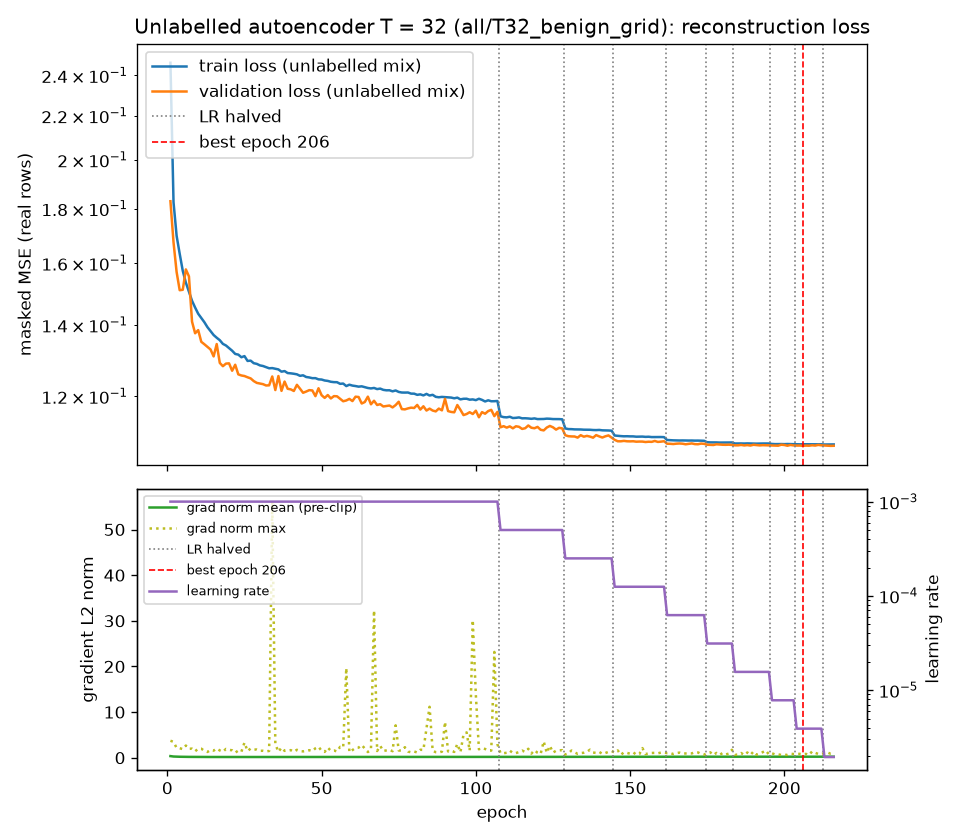

In [5]:
history = pd.read_json(RUN / "history.jsonl", lines=True)
print(f"best epoch {summary['best_epoch']} (val masked MSE {summary['best_val_loss']:.5f}); epochs run {summary['epochs_run']}; "
      f"stop: {summary['stop_reason']}; LR halvings {len(summary['lr_changes'])}; "
      f"training {summary['train_seconds'] / 60:.1f} min, whole train.py {summary['wall_seconds'] / 60:.1f} min on {summary['device']}; "
      f"median {history.seconds.median():.1f} s / epoch")
best_row = history[history.epoch == summary["best_epoch"]].iloc[0]
print(f"at the best epoch: train {best_row.train_loss:.5f}, val {best_row.val_loss:.5f} (val / train {best_row.val_loss / best_row.train_loss:.2f})")
Trainer.plot(history.to_dict("records"), summary["best_epoch"], summary["lr_changes"], RUN / "curves.png")
display(pd.concat([history.head(3), history.tail(3)]).set_index("epoch").round(5))
from IPython.display import Image
Image(str(RUN / "curves.png"), width=700)

## 4. Reconstruction on val (unlabelled)

The val scores written by `train.py`, re-computed here from `best.pt`; the val p95 / p99 thresholds re-derived and
compared with `summary.json`; three full val windows with their reconstruction; mean error per feature.

In [6]:
trainer = Trainer.from_checkpoint(RUN / "best.pt")
maha = Mahalanobis.from_state(np.load(RUN / "mahalanobis.npz"))
files = ScoreFiles(RUN)
val_out = trainer.score(val.x, val.mask, keep_recon=True)
val_saved = files.load("val")
assert np.array_equal(val_saved["ids"], val.ids)
assert np.allclose(val_saved["reconstruction"], val_out["error"], rtol=1e-3, atol=1e-5)
assert np.allclose(val_saved["mahalanobis"], maha.score(val_out["z"]), rtol=1e-3, atol=1e-4)
pooled = float((val_out["error"].astype(np.float64) * val.n_messages).sum() / val.n_messages.sum())
print(f"val windows {len(val):,}; pooled masked MSE {pooled:.5f} (run's best val loss {summary['best_val_loss']:.5f}); "
      f"mahalanobis: cond {summary['mahalanobis']['cond']:.1f}, shrinkage {summary['mahalanobis']['shrinkage']:g}")
val_tracks = TrackScores(val.tracks())
for name in SCORES:
    q = quantile_thresholds(val_saved[name], settings.threshold_quantiles)
    assert all(np.isclose(q[k], summary["thresholds"]["window"][name][k], rtol=1e-5) for k in q)
    for how, agg in val_tracks.aggregate(val_saved[name]).items():
        q = quantile_thresholds(agg, settings.threshold_quantiles)
        assert all(np.isclose(q[k], summary["thresholds"]["track"][f"{name}_{how}"][k], rtol=1e-5) for k in q)
print("val thresholds re-derived from the score files = summary.json")
display(pd.DataFrame(summary["thresholds"]["window"]).T.round(4))

show = ["claimed_pos_x", "claimed_vel_x", "range"]
picks = np.flatnonzero(val.n_messages == 32)[:3]
fig, axes = plt.subplots(len(picks), len(show), figsize=(12, 2.4 * len(picks)), squeeze=False)
for r, i in enumerate(picks):
    for c, f in enumerate(show):
        j = FEATURES.index(f)
        axes[r, c].plot(val.x[i, :, j], label="input")
        axes[r, c].plot(val_out["recon"][i, :, j], "--", label="reconstruction")
        axes[r, c].set_title(f, fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()
pd.Series(val_out["error_feature"].mean(0), index=FEATURES, name="val MSE").sort_values(ascending=False).round(4).to_frame().T

val windows 67,582; pooled masked MSE 0.10781 (run's best val loss 0.10781); mahalanobis: cond 46.9, shrinkage 0
val thresholds re-derived from the score files = summary.json


,p95,p99
reconstruction,0.3568,0.6041
mahalanobis,5.3774,6.7379


/var/folders/db/lskr0w394ng50mbc22ygfkn00000gn/T/ipykernel_50742/3201231769.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); plt.show()


,claimed_acl_x,claimed_acl_y,log_dtau,rx_vel_x,bearing,rx_vel_y,claimed_vel_y,claimed_vel_x,range,claimed_pos_x,claimed_pos_y,rx_pos_x,rx_pos_y
val MSE,0.309,0.3013,0.1999,0.1083,0.1015,0.0915,0.0647,0.0646,0.0352,0.019,0.017,0.0141,0.0138


## 5. Test

The test windows are read **without labels**, scored with `best.pt`, and checked against the score files written by
`evaluate.py` (`scores/test_*.npy`, aligned with `test_ids.npy`). No threshold or direction is chosen here: the
thresholds are the val p95 / p99 above, the length rule is score = −n_messages.

In [7]:
test = UnlabelledWindows.load(settings.data_dir, "test", settings.workers, cache_dir=settings.cache_dir)
test_out = trainer.score(test.x, test.mask)
saved = files.load("test")
assert np.array_equal(saved["ids"], test.ids) and np.array_equal(saved["n_messages"], test.n_messages)
assert np.allclose(saved["reconstruction"], test_out["error"], rtol=1e-3, atol=1e-5)
assert np.allclose(saved["mahalanobis"], maha.score(test_out["z"]), rtol=1e-3, atol=1e-4)
assert not (test.vehicles() & (train.vehicles() | val.vehicles())), "a test vehicle is in train or val"
print(f"test windows {len(test):,}; score files match a fresh scoring pass; no test vehicle in train / val")

test windows 67,100; score files match a fresh scoring pass; no test vehicle in train / val


Now the labels (`_info.json`, positive = GridSybil). The report is rebuilt with `Evaluation` from the score files and
compared with the stored `evaluation.json`. Class counts per split come from the info files (train / val labels are
read here for counting only).

In [8]:
labels = WindowLabels.load(settings.data_dir, "test", settings.workers)
labels.check(saved["ids"], saved["n_messages"])
ev = Evaluation({n: saved[n] for n in SCORES}, labels.y, saved["n_messages"], test.tracks(), labels.group, labels.scenario,
                summary["thresholds"])
grid_rows = labels.family == "GridSybil"
reports = {"all test windows": ev.report(), "GridSybil folders only": ev.report(grid_rows)}


def close(a, b):
    if isinstance(a, dict):
        return set(a) == set(b) and all(close(a[k], b[k]) for k in a)
    if isinstance(a, float):
        return bool(np.isclose(a, b, rtol=1e-9, atol=1e-12, equal_nan=True))
    return a == b


assert close(reports["all test windows"], stored["test_all"]) and close(reports["GridSybil folders only"], stored["test_gridsybil_folders"])
print("report rebuilt here = evaluation.json")
counts = pd.DataFrame(stored["class_counts"]).T[["benign", "gridsybil", "gridsybil_share"]]
display(counts.round(4))
pd.DataFrame({k: {"windows": r["windows"], "benign": r["benign"], "GridSybil": r["gridsybil"], "GridSybil share": round(r["gridsybil_share"], 4),
                  "1-3-row share": round(r["share_rows_1_3"], 4), "tracks": r["track"]["reconstruction"]["tracks"],
                  "mixed-label tracks": r["track"]["reconstruction"]["mixed_label_tracks"]} for k, r in reports.items()}).T

report rebuilt here = evaluation.json


,benign,gridsybil,gridsybil_share
test,45448.0,21652.0,0.3227
train,535501.0,243586.0,0.3127
val,47279.0,20303.0,0.3004


,windows,benign,GridSybil,GridSybil share,1-3-row share,tracks,mixed-label tracks
all test windows,67100.0,45448.0,21652.0,0.3227,0.1577,54102.0,0.0
GridSybil folders only,33614.0,11962.0,21652.0,0.6441,0.1787,27348.0,0.0


Window level, GridSybil vs benign: AUROC, PR-AUC (chance = GridSybil share), recall and benign FPR at the val p95 /
p99 thresholds; AUROC on the 1–3-row and the ≥ 4-row windows; per group. **Length alone** uses the fixed rule
score = −n_messages (shorter = more anomalous, the convention of `task/autoencoder_benign_t32`); the last column gives
what the `task/autoencoder_st_t32` convention (max(a, 1 − a), direction picked on the evaluated labels) would report.

In [9]:
rows = []
for subset, r in reports.items():
    for name in SCORES:
        w = r["window"][name]
        rows.append({"subset": subset, "score": name, "AUROC": w["auroc"], "PR-AUC": w["pr_auc"], "chance": w["chance"],
                     "recall p95": w["p95"]["recall"], "benign FPR p95": w["p95"]["benign_fpr"],
                     "recall p99": w["p99"]["recall"], "benign FPR p99": w["p99"]["benign_fpr"],
                     "AUROC 1-3 rows": w["rows_1_3"]["auroc"], "AUROC >= 4 rows": w["rows_ge_4"]["auroc"],
                     "AUROC 0709": w["by_group"]["0709"]["auroc"], "AUROC 1416": w["by_group"]["1416"]["auroc"]})
    lo = r["length_only"]
    rows.append({"subset": subset, "score": "length alone (-n_messages)", "AUROC": lo["auroc"], "PR-AUC": lo["pr_auc"],
                 "chance": r["gridsybil_share"], "AUROC best direction (st_t32 convention)": lo["auroc_best_direction"]})
window_table = pd.DataFrame(rows).set_index(["subset", "score"])
window_table.round(4)

AUROC  PR-AUC  chance  recall p95  benign FPR p95  recall p99  benign FPR p99  AUROC 1-3 rows  AUROC >= 4 rows  AUROC 0709  AUROC 1416  \
subset                 score                                                                                                                                                                 
all test windows       reconstruction              0.6102  0.4357  0.3227      0.1077          0.0404      0.0266          0.0068          0.4959           0.6485      0.6112      0.6049   
                       mahalanobis                 0.3977  0.3314  0.3227      0.0967          0.0527      0.0449          0.0033          0.3846           0.4142      0.3911      0.4221   
                       length alone (-n_messages)  0.5599  0.3734  0.3227         NaN             NaN         NaN             NaN             NaN              NaN         NaN         NaN   
GridSybil folders only reconstruction              0.6131  0.7415  0.6441      0.1077          0.0404      0.0266          0.0063          0.4908           0.6536      0.6141      0.6059   
                       mahalanobis                 0.3959  0.6286  0.6441      0.0967          0.0525      0.0449          0.0028          0.3823           0.4132      0.3886      0.4242   
                       length alone (-n_messages)  0.5636  0.6947  0.6441         NaN             NaN         NaN             NaN             NaN              NaN         NaN         NaN   

                                                   AUROC best direction (st_t32 convention)  
subset                 score                                                                 
all test windows       reconstruction                                                   NaN  
                       mahalanobis                                                      NaN  
                       length alone (-n_messages)                                    0.5599  
GridSybil folders only reconstruction                                                   NaN  
                       mahalanobis                                                      NaN  
                       length alone (-n_messages)                                    0.5636

Sanity check of the headline numbers with plain sklearn calls on the score files.

In [10]:
for name in SCORES:
    a, p = roc_auc_score(labels.y, saved[name]), average_precision_score(labels.y, saved[name])
    assert np.isclose(a, reports["all test windows"]["window"][name]["auroc"]) and np.isclose(p, reports["all test windows"]["window"][name]["pr_auc"])
    print(f"{name}: AUROC {a:.4f}, PR-AUC {p:.4f}; GridSybil folders only: AUROC {roc_auc_score(labels.y[grid_rows], saved[name][grid_rows]):.4f}")
print(f"length alone, fixed rule: AUROC {roc_auc_score(labels.y, -saved['n_messages'].astype(float)):.4f}")

reconstruction: AUROC 0.6102, PR-AUC 0.4357; GridSybil folders only: AUROC 0.6131
mahalanobis: AUROC 0.3977, PR-AUC 0.3314; GridSybil folders only: AUROC 0.3959
length alone, fixed rule: AUROC 0.5599


Per track (max / mean of a link's window scores), with the val track thresholds; per group counts and metrics.

In [11]:
rows = []
for subset, r in reports.items():
    for name in SCORES:
        for how in ("max", "mean"):
            t = r["track"][name][how]
            rows.append({"subset": subset, "score": name, "level": f"track {how}", "tracks": r["track"][name]["tracks"],
                         "AUROC": t["auroc"], "PR-AUC": t["pr_auc"], "chance": t["chance"], "recall p95": t["p95"]["recall"],
                         "benign FPR p95": t["p95"]["benign_fpr"], "recall p99": t["p99"]["recall"], "benign FPR p99": t["p99"]["benign_fpr"]})
display(pd.DataFrame(rows).set_index(["subset", "score", "level"]).round(4))
rows = []
for subset, r in reports.items():
    for name in SCORES:
        for g, d in r["window"][name]["by_group"].items():
            rows.append({"subset": subset, "score": name, "group": g, "benign": d["n_benign"], "GridSybil": d["n_gridsybil"],
                         "AUROC": d["auroc"], "PR-AUC": d["pr_auc"], "recall p95": d["p95"]["recall"], "benign FPR p95": d["p95"]["benign_fpr"]})
pd.DataFrame(rows).set_index(["subset", "score", "group"]).round(4)

tracks   AUROC  PR-AUC  chance  recall p95  benign FPR p95  recall p99  benign FPR p99
subset                 score          level                                                                                             
all test windows       reconstruction track max    54102  0.5945  0.4324  0.3287      0.1063          0.0404      0.0262          0.0069
                                      track mean   54102  0.5992  0.4357  0.3287      0.1056          0.0398      0.0237          0.0063
                       mahalanobis    track max    54102  0.3618  0.2974  0.3287      0.0695          0.0590      0.0297          0.0054
                                      track mean   54102  0.3623  0.2916  0.3287      0.0683          0.0590      0.0274          0.0078
GridSybil folders only reconstruction track max    27348  0.5990  0.7395  0.6504      0.1063          0.0408      0.0262          0.0067
                                      track mean   27348  0.6044  0.7439  0.6504      0.1056          0.0369      0.0237          0.0059
                       mahalanobis    track max    27348  0.3606  0.6021  0.6504      0.0695          0.0584      0.0297          0.0047
                                      track mean   27348  0.3607  0.6005  0.6504      0.0683          0.0596      0.0274          0.0058

benign  GridSybil   AUROC  PR-AUC  recall p95  benign FPR p95
subset                 score          group                                                               
all test windows       reconstruction 0709    36052      16909  0.6112  0.4378      0.0995          0.0341
                                      1416     9396       4743  0.6049  0.4325      0.1366          0.0646
                       mahalanobis    0709    36052      16909  0.3911  0.3235      0.0939          0.0526
                                      1416     9396       4743  0.4221  0.3629      0.1069          0.0531
GridSybil folders only reconstruction 0709     9611      16909  0.6141  0.7388      0.0995          0.0349
                                      1416     2351       4743  0.6059  0.7507      0.1366          0.0630
                       mahalanobis    0709     9611      16909  0.3886  0.6171      0.0939          0.0525
                                      1416     2351       4743  0.4242  0.6720      0.1069          0.0523

Benign false-positive rate per source folder at the val p95 / p99 window thresholds (all test windows). The same
benign traffic recurs in every family (F1); GridSybil_0709 is a separate re-simulation (F14).

In [12]:
r = reports["all test windows"]["benign_fpr_by_folder"]
fpr = pd.DataFrame({(name, q): {folder: d[q] for folder, d in r[name].items()} for name in SCORES for q in ("p95", "p99")})
fpr.insert(0, "benign windows", pd.Series({folder: d["n_benign"] for folder, d in r["reconstruction"].items()}))
fpr.round(4)

benign windows reconstruction         mahalanobis        
                                                  p95     p99         p95     p99
DataReplaySybil_0709              8799         0.0328  0.0048      0.0521  0.0031
DataReplaySybil_1416              2351         0.0651  0.0140      0.0536  0.0030
DoSDisruptiveSybil_0709           8821         0.0342  0.0051      0.0529  0.0040
DoSDisruptiveSybil_1416           2347         0.0652  0.0145      0.0533  0.0021
DoSRandomSybil_0709               8821         0.0342  0.0051      0.0529  0.0040
DoSRandomSybil_1416               2347         0.0652  0.0145      0.0533  0.0021
GridSybil_0709                    9611         0.0349  0.0047      0.0525  0.0029
GridSybil_1416                    2351         0.0630  0.0128      0.0523  0.0026

Score histograms per window (test, by class, read after scoring) with the val p95 threshold, and the median reconstruction error by window length.

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, name in zip(axes, SCORES):
    s = np.log10(np.maximum(saved[name], 1e-6))
    bins = np.linspace(np.quantile(s, 0.001), np.quantile(s, 0.999), 80)
    for v, lab, c in ((0, "benign", "tab:blue"), (1, "GridSybil", "tab:red")):
        ax.hist(s[labels.y == v], bins=bins, alpha=0.55, density=True, label=lab, color=c)
    ax.axvline(np.log10(summary["thresholds"]["window"][name]["p95"]), color="k", ls="--", lw=1, label="val p95")
    ax.set_xlabel(f"log10 {name} score"); ax.set_title(f"{name}: test windows", fontsize=10); ax.legend(fontsize=8)
df = pd.DataFrame({"n": saved["n_messages"], "e": saved["reconstruction"], "y": labels.y})
for v, lab, c in ((0, "benign", "tab:blue"), (1, "GridSybil", "tab:red")):
    g = df[df.y == v].groupby("n").e.median()
    axes[2].plot(g.index, g.values, marker=".", label=lab, color=c)
axes[2].set_yscale("log"); axes[2].set_xlabel("real messages per window"); axes[2].set_ylabel("median reconstruction error")
axes[2].set_title("reconstruction error by window length", fontsize=10); axes[2].legend(fontsize=8)
fig.tight_layout(); plt.show()

/var/folders/db/lskr0w394ng50mbc22ygfkn00000gn/T/ipykernel_50742/2020048219.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); plt.show()


Mean per-feature reconstruction error by class on the test windows, and the AUROC of each feature's error alone.

In [14]:
ef = test_out["error_feature"]
feat = pd.DataFrame({"mean error benign": ef[labels.y == 0].mean(0), "mean error GridSybil": ef[labels.y == 1].mean(0),
                     "AUROC of the feature's error": [roc_auc_score(labels.y, ef[:, j]) for j in range(ef.shape[1])]}, index=FEATURES)
feat.round(4)

,mean error benign,mean error GridSybil,AUROC of the feature's error
claimed_pos_x,0.0132,0.0416,0.6228
claimed_pos_y,0.0110,0.0378,0.6706
rx_pos_x,0.0139,0.0202,0.5619
rx_pos_y,0.0126,0.0199,0.5786
claimed_vel_x,0.0816,0.0407,0.3999
claimed_vel_y,0.0822,0.0393,0.3622
rx_vel_x,0.1063,0.1293,0.5367
rx_vel_y,0.0881,0.1187,0.5525
claimed_acl_x,0.3066,0.4261,0.5334
claimed_acl_y,0.2861,0.4149,0.5389


## 6. Context

Existing numbers of the two T = 32 siblings, read by `evaluate.py` from the result cells of their executed notebooks
(their `summary.json` files hold training / val fields only). The supervised study uses the same data, split and test
windows; **the one-class study uses a different split (`all/T32_benign`, 80 / 10 / 10) and test set**. One seed each:
these numbers frame the result, they do not rank the models.

In [15]:
ctx = stored["context"]
a = reports["all test windows"]
rows = {"this study: unlabelled mix, reconstruction": {"data / split": "all/T32_benign_grid 85 / 7.5 / 7.5", "training signal": "none (benign + GridSybil pooled)", "window AUROC": a["window"]["reconstruction"]["auroc"]},
        "this study: unlabelled mix, Mahalanobis": {"data / split": "all/T32_benign_grid 85 / 7.5 / 7.5", "training signal": "none (benign + GridSybil pooled)", "window AUROC": a["window"]["mahalanobis"]["auroc"]}}
if "supervised_st_t32" in ctx:
    rows["task/autoencoder_st_t32 (context)"] = {"data / split": "same data, split and test windows", "training signal": ctx["supervised_st_t32"]["training_signal"], "window AUROC": ctx["supervised_st_t32"]["window_auroc"]}
if "one_class_benign_t32" in ctx:
    rows["task/autoencoder_benign_t32, reconstruction (context)"] = {"data / split": "all/T32_benign 80 / 10 / 10 (different split and test set)", "training signal": ctx["one_class_benign_t32"]["training_signal"], "window AUROC": ctx["one_class_benign_t32"]["window_auroc_reconstruction"]}
pd.DataFrame(rows).T

,data / split,training signal,window AUROC
"this study: unlabelled mix, reconstruction",all/T32_benign_grid 85 / 7.5 / 7.5,none (benign + GridSybil pooled),0.610203
"this study: unlabelled mix, Mahalanobis",all/T32_benign_grid 85 / 7.5 / 7.5,none (benign + GridSybil pooled),0.397724
task/autoencoder_st_t32 (context),"same data, split and test windows",GridSybil labels (classifier head on z),0.9263
"task/autoencoder_benign_t32, reconstruction (context)",all/T32_benign 80 / 10 / 10 (different split a...,benign windows only,0.736


The numbers the analysis below refers to.

In [16]:
def brief(r):
    out = {"windows": r["windows"], "gridsybil_share": round(r["gridsybil_share"], 4), "length_only_auroc": round(r["length_only"]["auroc"], 4),
           "length_only_auroc_best_direction": round(r["length_only"]["auroc_best_direction"], 4)}
    for name in SCORES:
        w, t = r["window"][name], r["track"][name]
        out[name] = {"auroc": round(w["auroc"], 4), "pr_auc": round(w["pr_auc"], 4),
                     "recall_p95": round(w["p95"]["recall"], 4), "benign_fpr_p95": round(w["p95"]["benign_fpr"], 4),
                     "recall_p99": round(w["p99"]["recall"], 4), "benign_fpr_p99": round(w["p99"]["benign_fpr"], 4),
                     "auroc_rows_1_3": round(w["rows_1_3"]["auroc"], 4), "auroc_rows_ge_4": round(w["rows_ge_4"]["auroc"], 4),
                     "auroc_0709": round(w["by_group"]["0709"]["auroc"], 4), "auroc_1416": round(w["by_group"]["1416"]["auroc"], 4),
                     "track_max_auroc": round(t["max"]["auroc"], 4), "track_mean_auroc": round(t["mean"]["auroc"], 4)}
    return out


results = {"run": RUN.name, "params": summary["params"], "best_epoch": summary["best_epoch"], "best_val_loss": round(summary["best_val_loss"], 5),
           "epochs_run": summary["epochs_run"], "stop_reason": summary["stop_reason"], "lr_changes": len(summary["lr_changes"]),
           "train_minutes": round(summary["train_seconds"] / 60, 1), "train_gridsybil_share": round(stored["class_counts"]["train"]["gridsybil_share"], 4),
           "val_gridsybil_share": round(stored["class_counts"]["val"]["gridsybil_share"], 4),
           "test_all": brief(reports["all test windows"]), "test_gridsybil_folders": brief(reports["GridSybil folders only"])}
results

{'run': 'seed0',
 'params': 63293,
 'best_epoch': 206,
 'best_val_loss': 0.10781,
 'epochs_run': 216,
 'stop_reason': 'early_stopping',
 'lr_changes': 9,
 'train_minutes': 152.3,
 'train_gridsybil_share': 0.3127,
 'val_gridsybil_share': 0.3004,
 'test_all': {'windows': 67100,
  'gridsybil_share': 0.3227,
  'length_only_auroc': 0.5599,
  'length_only_auroc_best_direction': 0.5599,
  'reconstruction': {'auroc': 0.6102,
   'pr_auc': 0.4357,
   'recall_p95': 0.1077,
   'benign_fpr_p95': 0.0404,
   'recall_p99': 0.0266,
   'benign_fpr_p99': 0.0068,
   'auroc_rows_1_3': 0.4959,
   'auroc_rows_ge_4': 0.6485,
   'auroc_0709': 0.6112,
   'auroc_1416': 0.6049,
   'track_max_auroc': 0.5945,
   'track_mean_auroc': 0.5992},
  'mahalanobis': {'auroc': 0.3977,
   'pr_auc': 0.3314,
   'recall_p95': 0.0967,
   'benign_fpr_p95': 0.0527,
   'recall_p99': 0.0449,
   'benign_fpr_p99': 0.0033,
   'auroc_rows_1_3': 0.3846,
   'auroc_rows_ge_4': 0.4142,
   'auroc_0709': 0.3911,
   'auroc_1416': 0.4221,
   'tr

## 7. Analysis

One seed (0), a side experiment, not a thesis result (RULE 1). Numbers are from the cells above and
`runs/seed0/evaluation.json`.

- **Training.** 779,087 train windows pooled (GridSybil share 0.313, counted from the info files after scoring; never
  read in training). Best val masked MSE 0.1078 at epoch 206, early stopping at epoch 216 after 9 LR halvings (first
  after epoch 107). No overfitting (val / train 1.00 at the best epoch). Wall-clock 152 min on MPS, of which 5 epochs
  (13-16 and 92) took 104 min in total (the machine was shared with two other training jobs; epoch 15 alone took
  69 min); the other 211 epochs took 42 min (median 10.5 s / epoch).
- **Reconstruction error: a weak detector.** Window AUROC **0.610** (PR-AUC 0.436, chance 0.323) against 0.560 for
  window length alone. At the val p95 threshold recall is 0.108 with benign FPR 0.040; at val p99 0.027 / 0.007. The
  thresholds are quantiles of a val set that is itself 30% GridSybil, so "p95" is not a 5% benign false-alarm rate by
  construction (it came out at 4.0%).
- **All of the signal is in windows with ≥ 4 rows** (AUROC 0.649); on the 1–3-row windows (15.8% of test) the error
  is at chance (0.496). Per track it is no better (max 0.595, mean 0.599; 54,102 tracks, 0 mixed-label).
- **Mahalanobis on z is below chance** (window AUROC **0.398**, track 0.362): GridSybil is 31% of the data the
  Gaussian is fitted on and sits closer to the centre of z than benign traffic does. Same direction as
  `task/autoencoder_overlap` (0.337 with 64.5% GridSybil in train). The score is reported as defined; flipping its
  sign would be choosing the direction on test labels.
- **Groups and folders.** Reconstruction AUROC 0.611 (0709) / 0.605 (1416). Benign FPR at val p95 is 0.033–0.035 in
  every 0709 folder and 0.063–0.065 in every 1416 folder: it depends on the time window, not on the family, as
  expected when the same benign traffic recurs in every family (F1). The two DoS families give identical benign
  counts and rates.
- **GridSybil folders only** (33,614 windows, GridSybil share 0.644): reconstruction AUROC 0.613, Mahalanobis 0.396,
  length alone 0.564; ≥ 4 rows 0.654. Restricting the benign side to the GridSybil folders changes the AUROC by
  0.003: the repeated benign copies do not inflate or deflate the ranking. PR-AUC moves (0.741) only because the
  class share moves.
- **Length rule.** Fixed rule score = −n_messages gives 0.560 (all) / 0.564 (GridSybil folders). The
  `task/autoencoder_st_t32` convention (max(a, 1 − a)) gives the same numbers here, because the fixed direction is
  already the better one.
- **Context (one seed each, not a ranking).** Same data, split and test windows with GridSybil labels
  (`task/autoencoder_st_t32`): 0.926; the reconstruction error of that supervised model alone: 0.598. One-class
  training on benign only (`task/autoencoder_benign_t32`, a **different split and test set**): 0.736 (0.778 on ≥ 4
  rows), Mahalanobis 0.510. Leaving 31% GridSybil unlabelled in the training pool goes with a lower reconstruction
  AUROC than the one-class study reports (0.610 vs 0.736) and a Mahalanobis score below chance; the two studies
  differ in split, test set and normalisation, so the gap is an observation, not a controlled comparison.
- **Caveats.** One seed, no confidence interval. F14: GridSybil_0709 is a re-simulation whose near-copies of other
  0709 cars can straddle the split (not measured here). F1: benign traffic appears once per family (≈ 4×), so window
  counts are not independent. F13: track ids contain the true sender (used for aggregation only, never as input).
  GridSybil only: nothing here speaks to DataReplay / DoS.